# Clase 8 — Transfer learning y fine-tuning con imágenes propias
**Jaime Andrés Jaramillo Ramírez**

En este taller trabajé con tres clases: **bicicletas, buses y motocicletas**. La idea fue aprovechar lo que EfficientNetB0 ya aprendió con ImageNet y adaptarlo a estas imágenes. Primero entrené la parte final del modelo con la base congelada y después hice fine-tuning para comparar los resultados.

Se descargaron 289 imágenes y, después de la revisión, se descartaron 126. Quedaron 163: 61 de bicicletas, 44 de buses y 58 de motocicletas. La separación quedó en 112 para entrenamiento, 23 para validación y 28 para prueba. Antes y después del fine-tuning se acertaron **27 de las 28 imágenes de test (96,43 %)**, con un **F1 macro de 0,9666**. La pérdida de validación bajó de 0,1650 a 0,1538, por lo que se conservó el modelo ajustado.

Hay algunas limitaciones que debo tener en cuenta. No se alcanzaron las 100–150 imágenes útiles por clase que se buscaban al inicio. Además, al revisar las imágenes pequeñas se pasaron algunas marcas de agua y no fue posible comprobar si todas eran fotografías reales. Como el test solo tiene 28 imágenes, este resultado no asegura que el modelo funcione igual de bien en otros casos.

Para analizar cinco errores se tomó uno de test, dos de validación, uno de entrenamiento y uno de una imagen descartada que se probó aparte. En el análisis se indica de dónde viene cada caso, para no confundirlos con cinco errores de test.

Para volver a ejecutar el trabajo, hay que extraer `clase_8_completa.zip` y abrir el notebook desde esa carpeta. En Colab conviene usar GPU y ejecutar las celdas en orden. Los modelos quedan en `artifacts` y los reportes en `reports`. Si se descargan otras imágenes, los resultados pueden cambiar; los valores que comento aquí son los de esta ejecución.

La configuración del fine-tuning se definió antes de revisar test. Después de ver los resultados solo se analizaron los errores, sin volver a entrenar ni cambiar el modelo elegido.


## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [ ]:
%pip -q install "tensorflow>=2.16,<2.22" "keras>=3,<4" "ddgs>=9,<10" requests pillow pandas scikit-learn matplotlib


In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time, json
import pandas as pd
from PIL import ImageOps
from IPython.display import display, Markdown
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
keras.utils.set_random_seed(SEED)
REPORTS_DIR = Path("reports"); REPORTS_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR = Path("artifacts"); ARTIFACTS_DIR.mkdir(exist_ok=True)
# Dejo estos valores definidos antes de revisar el conjunto de prueba.
N_UNFROZEN = 20
FT_EPOCHS = 5


Keras: 3.15.1
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [2]:
SEARCHES = {
    "bicycle": ["bicycle full view photograph", "city bicycle outdoors photo", "mountain bicycle parked photo"],
    "bus": ["city bus full view photograph", "coach bus road photograph", "public transport bus street photo"],
    "motorcycle": ["motorcycle full view photograph", "street motorcycle parked photo", "touring motorcycle road photo"],
}
SEARCHES


### Problema y estrategia de búsqueda

Elegí estas tres clases porque tienen diferencias que se pueden reconocer en una imagen. En las bicicletas espero que el modelo se fije en el cuadro, los pedales y la ausencia de motor. En las motocicletas, en el motor, el tanque y la carrocería. En los buses, en su tamaño, las ventanas y la forma de la carrocería. También busqué distintos escenarios para que el modelo no aprenda a clasificar solo por el fondo.

En las búsquedas pueden aparecer juguetes, dibujos, anuncios, logos o fotos con varios vehículos. Las bicicletas eléctricas también pueden generar dudas. Por eso no basta con guardar una imagen en una carpeta: hay que revisar si realmente corresponde a esa clase y si se distingue el vehículo principal.

Un problema sería tener copias o recortes de la misma foto en entrenamiento y prueba. Eso podría hacer que el resultado se vea mejor de lo que realmente es. Para reducir este riesgo reviso duplicados antes de separar los datos. También guardo la URL y la búsqueda de cada descarga para tener una referencia de su origen. Las marcas de agua y los fondos repetidos son otros detalles que pueden influir en el modelo.


# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [3]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def canonical_image(img):
    img = ImageOps.exif_transpose(img).convert("RGB")
    img.thumbnail((1200, 1200))
    return img

def pixel_digest(img):
    return hashlib.sha256(str(img.size).encode() + img.tobytes()).hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60,
                           min_side=120, timeout=10, target_per_class=150):
    root = Path(root)
    manifest_path = REPORTS_DIR / "download_manifest.csv"
    rows = pd.read_csv(manifest_path).to_dict("records") if manifest_path.exists() else []
    seen = set()
    for p in root.glob("*/*.jpg"):
        try:
            with Image.open(p) as im:
                seen.add(pixel_digest(canonical_image(im)))
        except Exception:
            pass  # Más adelante reviso si este archivo se puede abrir.
    from concurrent.futures import ThreadPoolExecutor
    def fetch(result):
        url = result.get("image")
        if not url:
            return result, None, "URL ausente"
        try:
            with requests.get(url, timeout=timeout, stream=True, headers={"User-Agent": "Mozilla/5.0"}) as response:
                response.raise_for_status()
                data = bytearray()
                for chunk in response.iter_content(65536):
                    data.extend(chunk)
                    if len(data) > 12_000_000:
                        raise ValueError("Archivo demasiado grande")
            return result, data, None
        except Exception as exc:
            return result, None, str(exc)[:180]
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})
    failures = []
    for class_name, queries in searches.items():
        folder = root / class_name; folder.mkdir(parents=True, exist_ok=True)
        for query in queries:
            if len(list(folder.glob("*.jpg"))) >= target_per_class:
                break
            try:
                results = list(DDGS(timeout=timeout).images(
                    query=query, safesearch="moderate", max_results=images_per_query,
                    license_image="any"))
            except Exception as exc:
                failures.append({"query": query, "url": "", "error": str(exc)[:180]})
                continue
            with ThreadPoolExecutor(max_workers=8) as pool:
                downloaded = list(pool.map(fetch, results))
            for result, data, error in downloaded:
                if len(list(folder.glob("*.jpg"))) >= target_per_class:
                    break
                url = result.get("image")
                if not url:
                    continue
                try:
                    if error:
                        raise ValueError(error)
                    with Image.open(io.BytesIO(data)) as im:
                        img = canonical_image(im)
                    if min(img.size) < min_side:
                        continue
                    digest = pixel_digest(img)
                    if digest in seen:
                        continue
                    path = folder / f"{digest[:24]}.jpg"
                    img.save(path, "JPEG", quality=90)
                    seen.add(digest)
                    # También guardo el hash de la imagen convertida a JPG para no repetirla
                    # si vuelvo a ejecutar la descarga.
                    with Image.open(path) as saved:
                        seen.add(pixel_digest(canonical_image(saved)))
                    rows.append({"path": str(path), "class": class_name,
                                 "query": query, "image_url": url,
                                 "source_page": result.get("url", ""),
                                 "license_status": "Filtro solicitado; licencia individual no verificada"})
                except Exception as exc:
                    failures.append({"query": query, "url": url, "error": str(exc)[:180]})
            print(class_name, len(list(folder.glob("*.jpg"))), "imágenes")
            time.sleep(0.5)
    session.close()
    pd.DataFrame(rows, columns=["path", "class", "query", "image_url", "source_page", "license_status"]).to_csv(manifest_path, index=False)
    pd.DataFrame(failures, columns=["query", "url", "error"]).to_csv(REPORTS_DIR / "download_failures.csv", index=False)
    print("Descarga terminada. Fallos:", len(failures))


## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [4]:
# Si ya están las fotos de las tres clases, no las descargo otra vez.
DOWNLOAD_IMAGES = not all(any((RAW_DIR / c).glob("*.jpg")) for c in SEARCHES)
if DOWNLOAD_IMAGES:
    download_image_dataset(SEARCHES, images_per_query=60, target_per_class=100)


In [5]:
def count_images(root):
    root = Path(root)
    return {folder.name: len(list(folder.glob("*.jpg")))
            for folder in sorted(root.iterdir()) if folder.is_dir()}
counts_before = count_images(RAW_DIR)
display(pd.Series(counts_before, name="imágenes descargadas").to_frame())
if any(counts_before.get(c, 0) < 20 for c in SEARCHES):
    raise RuntimeError("Datos insuficientes: revisar reports/download_failures.csv o cargar fotos JPG en las tres carpetas de data_raw. Objetivo: 100–150 por clase.")


,imágenes descargadas
bicycle,100
bus,89
motorcycle,100


## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [6]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Intento leer la imagen completa para comprobar que no esté dañada.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        target = Path("quarantine") / "invalid" / path.parent.name
        target.mkdir(parents=True, exist_ok=True)
        shutil.move(str(path), str(target / path.name))

    print(f"\nImágenes inválidas apartadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)
invalid_count = len(bad_files)



Imágenes inválidas apartadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [7]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas apartadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

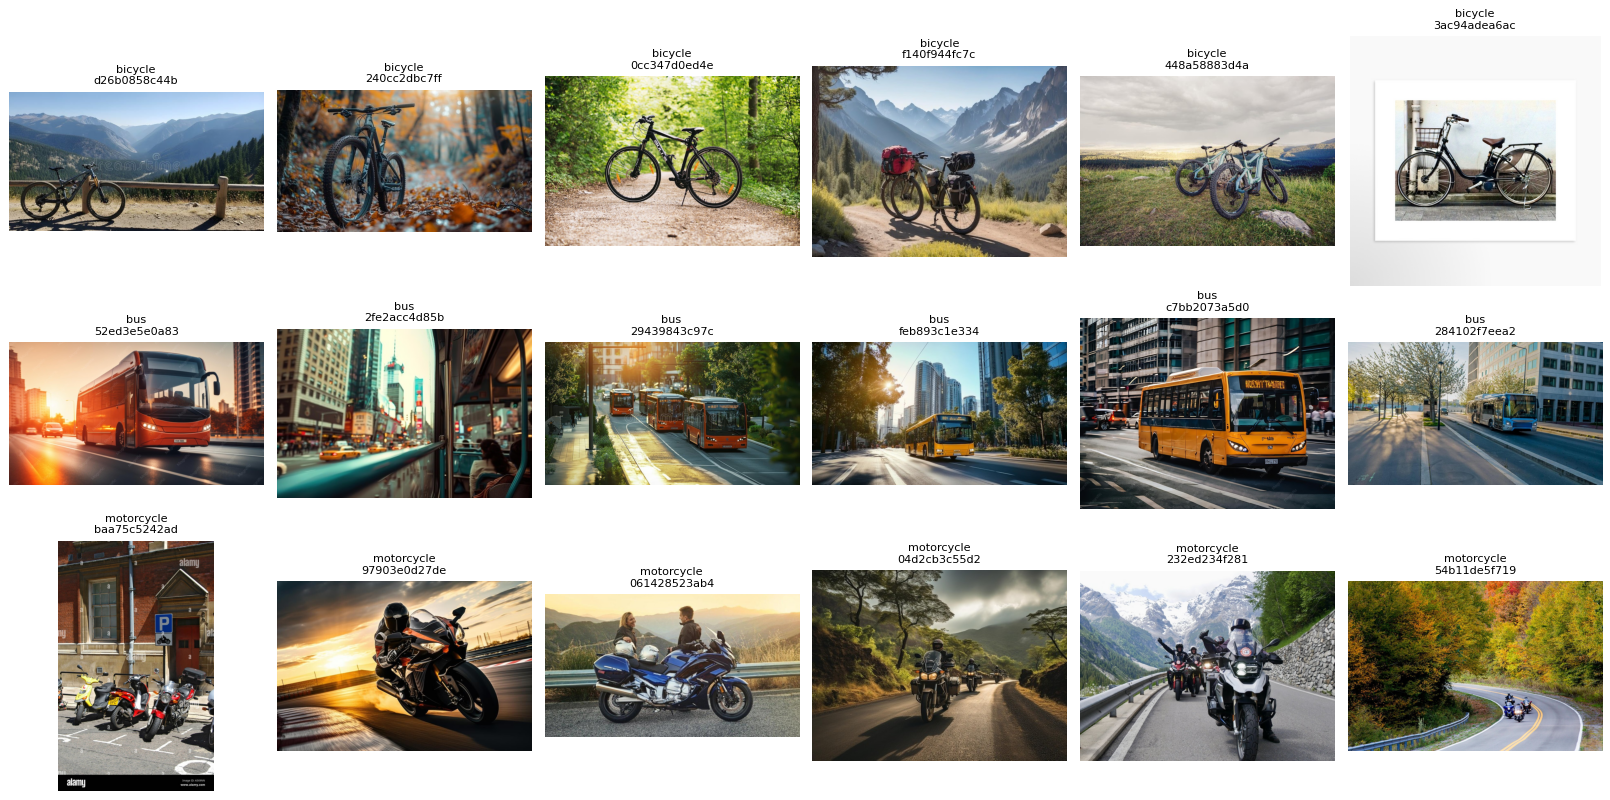

In [8]:
def show_random_images(root, n_per_class=6):
    folders = [Path(root) / c for c in sorted(SEARCHES)]
    fig, axes = plt.subplots(len(folders), n_per_class,
                             figsize=(3*n_per_class, 3*len(folders)), squeeze=False)
    rng = random.Random(SEED)
    for row, folder in enumerate(folders):
        files = sorted(folder.glob("*.jpg"))
        chosen = rng.sample(files, min(n_per_class, len(files)))
        for col, ax in enumerate(axes[row]):
            if col < len(chosen):
                with Image.open(chosen[col]) as im:
                    ax.imshow(im)
                ax.set_title(f"{folder.name}\n{chosen[col].name[:12]}", fontsize=9)
            ax.axis("off")
    plt.tight_layout(); plt.show()
show_random_images(RAW_DIR)


### Limpieza de imágenes y revisión de duplicados

Primero miro una muestra para tener una idea de lo que se descargó. Después genero galerías con todas las fotos y guardo la revisión en `reports/semantic_review.csv`. Cada imagen comienza como `pendiente`; luego se puede marcar como `conservar` o `eliminar` y escribir el motivo. Al ejecutar de nuevo la celda, las descartadas quedan en una carpeta aparte y no se incluyen en los datos usados para el modelo.

La comparación automática ayuda a encontrar fotos parecidas, pero no reemplaza la revisión visual. Dos imágenes similares no siempre son copias. El problema de calidad más frecuente se obtiene de los motivos registrados; si todavía no se ha revisado, queda indicado como pendiente.


In [9]:
# Comparo las imágenes para buscar copias muy parecidas antes de hacer el split.
def dhash(path):
    with Image.open(path) as im:
        a = np.asarray(ImageOps.exif_transpose(im).convert("L").resize((9, 8)), dtype=int)
    return sum(int(v) << i for i, v in enumerate((a[:, 1:] > a[:, :-1]).ravel()))

kept, duplicate_rows = [], []
for path in sorted(RAW_DIR.glob("*/*.jpg")):
    h = dhash(path)
    match = next((p for p, old in kept if (h ^ old).bit_count() <= 2), None)
    if match is not None:
        destination = Path("quarantine") / "near_duplicates" / path.parent.name
        destination.mkdir(parents=True, exist_ok=True)
        duplicate_rows.append({"removed": str(path), "similar_to": str(match)})
        shutil.copy2(path, destination / path.name)
    else:
        kept.append((path, h))
pd.DataFrame(duplicate_rows, columns=["removed", "similar_to"]).to_csv(REPORTS_DIR / "duplicate_candidates.csv", index=False)
review_path = REPORTS_DIR / "semantic_review.csv"
review = pd.read_csv(review_path).fillna("") if review_path.exists() else pd.DataFrame(columns=["path", "decision", "reason"])
known = set(review["path"])
new = [{"path": str(p), "decision": "pendiente", "reason": ""}
       for p in sorted(RAW_DIR.glob("*/*.jpg")) if str(p) not in known]
review = pd.concat([review, pd.DataFrame(new)], ignore_index=True)
removed_semantic = 0
for row in review.to_dict("records"):
    p = Path(row["path"])
    if row["decision"].strip().lower() == "eliminar" and p.exists():
        if RAW_DIR.resolve() not in p.resolve().parents:
            raise ValueError("La revisión contiene una ruta fuera de data_raw")
        destination = Path("quarantine") / "semantic" / p.parent.name
        destination.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, destination / p.name); removed_semantic += 1
review.to_csv(review_path, index=False)
gallery_dir = REPORTS_DIR / "galleries"; gallery_dir.mkdir(exist_ok=True)
for name in sorted(SEARCHES):
    paths = sorted((RAW_DIR / name).glob("*.jpg"))
    for start in range(0, len(paths), 24):
        fig, axes = plt.subplots(4, 6, figsize=(18, 12))
        for j, ax in enumerate(axes.ravel()):
            if start+j < len(paths):
                p = paths[start+j]
                with Image.open(p) as im: ax.imshow(im)
                ax.set_title(p.name, fontsize=6)
            ax.axis("off")
        fig.suptitle(name); fig.tight_layout()
        fig.savefig(gallery_dir / f"{name}_{start//24+1:02}.jpg", dpi=110); plt.close(fig)
# Guardo aparte las imágenes que sí voy a usar.
# Así las descartadas no entran al entrenamiento, aunque sigan guardadas.
excluded = set(review.loc[review["decision"].str.lower() == "eliminar", "path"])
excluded.update(row["removed"] for row in duplicate_rows)
approved_paths = [p for p in sorted(RAW_DIR.glob("*/*.jpg")) if str(p) not in excluded]
fingerprint = hashlib.sha256("\n".join(str(p) for p in approved_paths).encode()).hexdigest()[:12]
CLEAN_DIR = Path("data_clean_" + fingerprint)
for name in SEARCHES:
    (CLEAN_DIR / name).mkdir(parents=True, exist_ok=True)
for p in approved_paths:
    shutil.copy2(p, CLEAN_DIR / p.parent.name / p.name)
final_counts = count_images(CLEAN_DIR)
quality = {"counts": final_counts, "invalid_removed": invalid_count,
           "near_duplicate_candidates_removed_this_run": len(duplicate_rows),
           "semantic_removed_this_run": removed_semantic,
           "semantic_review_pending": int((review["decision"] == "pendiente").sum())}
(REPORTS_DIR / "data_quality.json").write_text(json.dumps(quality, indent=2), encoding="utf-8")
display(pd.Series(final_counts, name="imágenes finales").to_frame())
print("Control de calidad:", quality)
reasons = review.loc[review["decision"] == "eliminar", "reason"]
print("Motivo más frecuente:", reasons.value_counts().index[0] if len(reasons) else "No documentado: revisión semántica pendiente o sin exclusiones.")
if min(final_counts.values()) < 100:
    print("Aviso: alguna clase no alcanza el objetivo de 100 imágenes útiles; ampliar con diversidad.")


,imágenes finales
bicycle,61
bus,44
motorcycle,58


Control de calidad: {'counts': {'bicycle': 61, 'bus': 44, 'motorcycle': 58}, 'invalid_removed': 0, 'near_duplicate_candidates_removed_this_run': 0, 'semantic_removed_this_run': 126, 'semantic_review_pending': 0}
Motivo más frecuente: Contenido problemático: marca de agua, ilustración/estilo artificial o vehículo no identificable en revisión visual
Aviso: alguna clase no alcanza el objetivo de 100 imágenes útiles; ampliar con diversidad.


# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [10]:
SPLIT_DIR = Path("dataset_" + fingerprint)

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root, destination_root = Path(source_root), Path(destination_root)
    assert train_ratio > 0 and val_ratio > 0 and train_ratio + val_ratio < 1
    if destination_root.exists():
        # Vuelvo a crear las carpetas del split de este ejercicio.
        if destination_root.resolve() != (Path.cwd() / ("dataset_" + fingerprint)).resolve():
            raise ValueError("Ruta de salida inesperada")
        shutil.rmtree(destination_root)
    rng = random.Random(seed); rows = []
    for name in sorted(SEARCHES):
        files = sorted((source_root / name).glob("*.jpg"))
        if len(files) < 20:
            raise ValueError(f"La clase {name} tiene menos de 20 imágenes; completar el dataset")
        rng.shuffle(files); n = len(files)
        a, b = int(n*train_ratio), int(n*val_ratio)
        for split, selected in {"train": files[:a], "validation": files[a:a+b], "test": files[a+b:]}.items():
            target = destination_root / split / name; target.mkdir(parents=True, exist_ok=True)
            for src in selected:
                dst = target / src.name; shutil.copy2(src, dst)
                rows.append({"source": str(src), "path": str(dst), "split": split,
                             "class": name, "sha256": file_sha256(dst)})
    manifest = pd.DataFrame(rows)
    assert manifest.groupby("sha256")["split"].nunique().max() == 1, "Hay duplicados entre particiones"
    manifest.to_csv(REPORTS_DIR / "split_manifest.csv", index=False)
    return manifest
split_manifest = split_dataset(CLEAN_DIR, SPLIT_DIR)
display(pd.crosstab(split_manifest["class"], split_manifest["split"]))


split,test,train,validation
class,,,
bicycle,10,42,9
bus,8,30,6
motorcycle,10,40,8


### Comprobación conceptual

Si uso test varias veces para elegir las épocas, la tasa de aprendizaje o las capas que voy a descongelar, termino tomando decisiones para que el modelo funcione bien en ese conjunto. Aunque no lo use directamente para entrenar, ya estaría aprovechando su información y el resultado podría ser demasiado optimista.

Por eso dejé definidas las últimas 20 capas y las cinco épocas de fine-tuning antes de mirar test. Para detener el entrenamiento y escoger entre las dos versiones utilicé validación.


# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
assert class_names == val_ds.class_names == sorted(SEARCHES)
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
print(class_names)


Found 112 files belonging to 3 classes.
Found 23 files belonging to 3 classes.
['bicycle', 'bus', 'motorcycle']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)      

## 3. Entrenamiento de la cabeza de clasificación

Espero que la accuracy de entrenamiento suba relativamente rápido, porque la base ya aprendió características de imágenes con ImageNet. De todas formas, esto depende de la calidad de las fotos y de sus etiquetas. Si la accuracy de entrenamiento sigue subiendo, pero la de validación se queda igual y su pérdida aumenta, sería una señal de sobreajuste.

Para esta parte usé Adam con una tasa de 0,001 y un máximo de diez épocas. EarlyStopping revisa `val_loss` y espera dos épocas sin mejora antes de detenerse. Además, recupera los pesos de la mejor época. Dejé los píxeles entre 0 y 255 porque EfficientNetB0 ya incluye la normalización; no hace falta dividirlos otra vez por 255.


In [13]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
history = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stopping])
model.save(ARTIFACTS_DIR / "frozen_model.keras")
val_before = model.evaluate(val_ds, verbose=0, return_dict=True)
pd.DataFrame(history.history).to_csv(REPORTS_DIR / "history_frozen.csv", index=False)


/root/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.3482 - loss: 1.1282 - val_accuracy: 0.5217 - val_loss: 0.8564
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 556ms/step - accuracy: 0.6875 - loss: 0.8298 - val_accuracy: 0.8696 - val_loss: 0.6321
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 768ms/step - accuracy: 0.8214 - loss: 0.6129 - val_accuracy: 0.9130 - val_loss: 0.4708
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.8929 - loss: 0.4834 - val_accuracy: 0.9130 - val_loss: 0.3646
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 756ms/step - accuracy: 0.9464 - loss: 0.3758 - val_accuracy: 0.9130 - val_loss: 0.2934
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 520ms/s

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

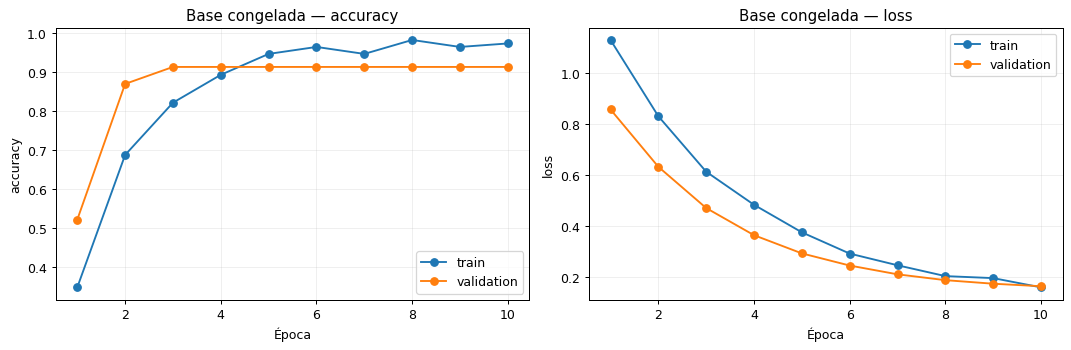

In [14]:
def plot_history(history, title):
    h = history.history; epochs = range(1, len(h["loss"])+1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(epochs, h[metric], marker="o", label="train")
        ax.plot(epochs, h["val_"+metric], marker="o", label="validation")
        ax.set(xlabel="Época", ylabel=metric, title=title+" — "+metric)
        ax.legend(); ax.grid(alpha=0.2)
    plt.tight_layout(); plt.show()
plot_history(history, "Base congelada")


# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [x] 3 clases definidas;
- [x] términos de búsqueda documentados;
- [x] imágenes descargadas;
- [x] dataset inspeccionado y parcialmente limpiado;
- [x] separación `train / validation / test`;
- [x] EfficientNetB0 con pesos de ImageNet;
- [x] backbone congelado;
- [x] nueva cabeza de clasificación;
- [x] al menos un entrenamiento completado;
- [x] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
# Ahora sí cargo test. No mezclo las imágenes para mantener su orden.
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False, class_names=class_names)
test_paths = list(test_ds.file_paths)
test_ds = test_ds.prefetch(AUTOTUNE)
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")


Found 28 files belonging to 3 classes.
Test accuracy antes del fine-tuning: 0.9643


              precision    recall  f1-score   support

     bicycle      1.000     0.900     0.947        10
         bus      1.000     1.000     1.000         8
  motorcycle      0.909     1.000     0.952        10

    accuracy                          0.964        28
   macro avg      0.970     0.967     0.967        28
weighted avg      0.968     0.964     0.964        28



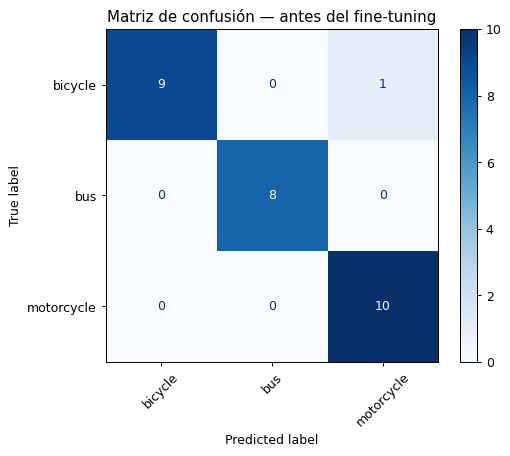

In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=class_names, digits=3, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()


## 4. Interpretación de la evaluación

En la siguiente celda reviso cuál clase tiene el mejor F1, qué clases se confunden más y cuál tiene el menor recall. Así puedo ver si la accuracy general está ocultando dificultades con alguna clase. También se tienen en cuenta los empates y el caso en que no haya errores.

Antes de cambiar la arquitectura, revisaría las etiquetas y las fotos de las clases que más se confunden. Buscaría si hay varios vehículos en una misma imagen o si el fondo se repite mucho en una clase. También añadiría bicicletas y motocicletas vistas desde lejos, parcialmente tapadas y desde distintos ángulos. Estos cambios serían para otro experimento, sin volver a ajustar el modelo con el mismo test.


In [17]:
report_before = classification_report(y_true, y_pred, labels=range(NUM_CLASSES),
                                      target_names=class_names, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report_before).T.loc[class_names]
display(per_class)
best_f1 = per_class["f1-score"].max()
print("Mejor F1:", ", ".join(per_class.index[np.isclose(per_class["f1-score"], best_f1)]), f"({best_f1:.3f})")
off = cm.copy(); np.fill_diagonal(off, 0)
if off.max() > 0:
    pairs = np.argwhere(off == off.max())
    print("Principal(es) confusión(es):", [(class_names[a], class_names[b], int(off[a,b])) for a,b in pairs])
else:
    print("No hubo confusiones observadas.")
worst = per_class["recall"].idxmin()
print(f"Menor recall: {worst}, {per_class.loc[worst, 'recall']:.3f}; accuracy global: {test_acc_before:.3f}.")
print("La accuracy pondera cada imagen por igual; revisar recall y F1 por clase evita ocultar fallos concentrados en una clase.")
per_class.to_csv(REPORTS_DIR / "class_metrics_before.csv")


,precision,recall,f1-score,support
bicycle,1.000000,0.9,0.947368,10.0
bus,1.000000,1.0,1.000000,8.0
motorcycle,0.909091,1.0,0.952381,10.0


Mejor F1: bus (1.000)
Principal(es) confusión(es): [('bicycle', 'motorcycle', 1)]
Menor recall: bicycle, 0.900; accuracy global: 0.964.
La accuracy pondera cada imagen por igual; revisar recall y F1 por clase evita ocultar fallos concentrados en una clase.


# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [18]:
# Uso las 20 capas que había definido antes de mirar test.
base_model.trainable = True
assert 0 < N_UNFROZEN <= len(base_model.layers)
for i, layer in enumerate(base_model.layers):
    layer.trainable = i >= len(base_model.layers)-N_UNFROZEN
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
print("Capas entrenables de la base:", sum(layer.trainable for layer in base_model.layers), "/", len(base_model.layers))
print("Parámetros entrenables:", sum(int(np.prod(v.shape)) for v in model.trainable_weights))


Capas entrenables de la base: 15 / 238
Parámetros entrenables: 1346611


## 5. Fine-tuning y justificación

Decidí empezar con las últimas 20 capas para hacer un ajuste pequeño y conservar la mayor parte de lo aprendido con ImageNet. Esto no significa que se actualicen 20 capas con pesos, porque algunas no tienen parámetros y las de BatchNormalization se mantienen congeladas.

Después recompilé el modelo con Adam y una tasa de 0,00001, que es cien veces menor que la usada al principio. La idea es que los pesos cambien poco a poco. Dejé un máximo de cinco épocas y usé EarlyStopping con `val_loss`.

Para decidir si me quedo con el fine-tuning comparo la pérdida de validación de las dos versiones. Si no mejora, conservo el modelo con la base congelada. La accuracy de test no se usa para tomar esa decisión.


/root/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
Epoch 1/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9821 - loss: 0.1549 - val_accuracy: 0.9130 - val_loss: 0.1623
Epoch 2/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 740ms/step - accuracy: 0.9732 - loss: 0.1568 - val_accuracy: 0.9130 - val_loss: 0.1610
Epoch 3/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 689ms/step - accuracy: 0.9821 - loss: 0.1580 - val_accuracy: 0.9130 - val_loss: 0.1582
Epoch 4/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 666ms/step - accuracy: 0.9911 - loss: 0.1233 - val_accuracy: 0.9130 - val_loss: 0.1558
Epoch 5/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 666ms/step - accuracy: 0.9911 - loss: 0.1293 - val_accuracy: 0.9130 - val_loss: 0.1538


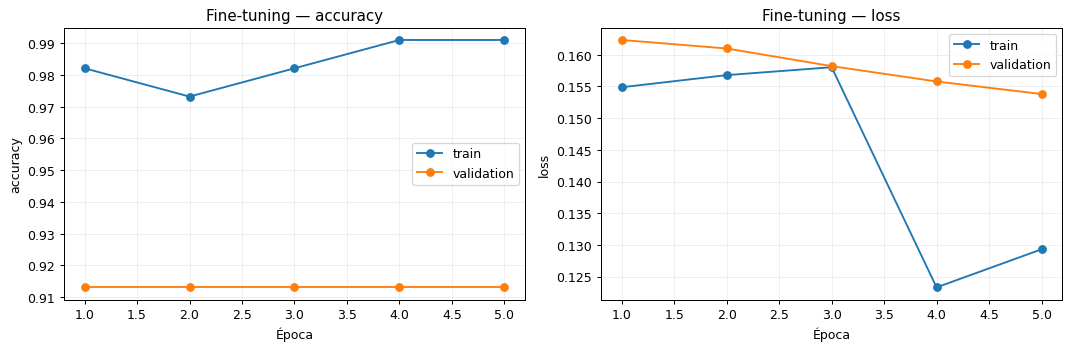

Versión seleccionada solo con validation: finetuned
Validation antes: {'accuracy': 0.9130434989929199, 'loss': 0.1649676412343979} Validation después: {'accuracy': 0.9130434989929199, 'loss': 0.1538020521402359}


In [19]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
              loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
early_stopping_ft = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS,
                       callbacks=[early_stopping_ft])
model.save(ARTIFACTS_DIR / "finetuned_model.keras")
val_after = model.evaluate(val_ds, verbose=0, return_dict=True)
pd.DataFrame(history_ft.history).to_csv(REPORTS_DIR / "history_finetuning.csv", index=False)
plot_history(history_ft, "Fine-tuning")
selected_stage = "finetuned" if val_after["loss"] < val_before["loss"] else "frozen"
selected_path = ARTIFACTS_DIR / ("finetuned_model.keras" if selected_stage == "finetuned" else "frozen_model.keras")
shutil.copy2(selected_path, ARTIFACTS_DIR / "selected_model.keras")
print("Versión seleccionada solo con validation:", selected_stage)
print("Validation antes:", val_before, "Validation después:", val_after)


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [20]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9643
Después del fine-tuning: 0.9643
Diferencia              : +0.0000


              precision    recall  f1-score   support

     bicycle      1.000     0.900     0.947        10
         bus      1.000     1.000     1.000         8
  motorcycle      0.909     1.000     0.952        10

    accuracy                          0.964        28
   macro avg      0.970     0.967     0.967        28
weighted avg      0.968     0.964     0.964        28



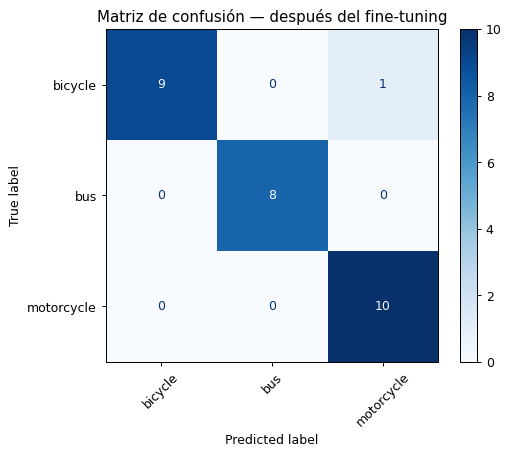

In [21]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, labels=range(NUM_CLASSES), target_names=class_names, digits=3, zero_division=0))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft, labels=range(NUM_CLASSES))
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()


# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

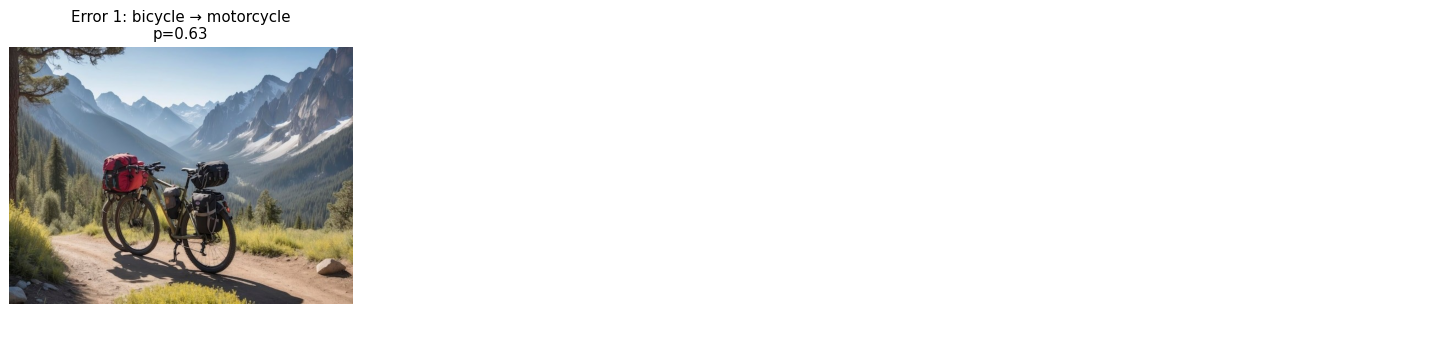

,image,real,prediction,confidence,probable_cause_unverified,improvement,human_observation
0,dataset_8c8e855ccf33/test/bicycle/f140f944fc7c...,bicycle,motorcycle,0.631028,Hipótesis: siluetas de dos ruedas similares; r...,Añadir vistas diversas y ejemplos difíciles de...,Pendiente de inspección


Errores reales disponibles: 1
Hay menos de cinco errores en test. Se muestran todos; no se inventan errores ni se cambia el modelo para producirlos.


In [22]:
# Uso las predicciones que ya calculé y el mismo orden de las imágenes.
error_indices = np.flatnonzero(y_true_ft != y_pred_ft)
error_indices = error_indices[np.argsort(-probabilities_ft[error_indices].max(axis=1))]
error_rows = []
for i in error_indices:
    p = Path(test_paths[i])
    with Image.open(p) as im:
        gray = np.asarray(im.convert("L"), dtype=float)
        width, height = im.size
    true, pred = class_names[y_true_ft[i]], class_names[y_pred_ft[i]]
    # Estas son posibles razones del error; hay que compararlas con la foto.
    if min(width, height) < 224:
        cause = "Resolución inferior a la entrada de la red; posible pérdida de detalle al ampliar."
        action = "Conseguir fotos de mayor resolución y comparar casos semejantes."
    elif gray.std() < 25:
        cause = "Bajo contraste global medido; comprobar iluminación y visibilidad del vehículo."
        action = "Añadir variaciones de iluminación y revisar el objeto en la fotografía."
    elif {true, pred} == {"bicycle", "motorcycle"}:
        cause = "Hipótesis: siluetas de dos ruedas similares; revisar visibilidad de motor y pedales."
        action = "Añadir vistas diversas y ejemplos difíciles de ambas clases, con etiquetas revisadas."
    else:
        cause = "Causa no determinada: revisar objeto principal, etiqueta, fondo y oclusión."
        action = "Inspeccionar la foto y ampliar ejemplos equivalentes en una siguiente versión."
    error_rows.append({"image": str(p), "real": true, "prediction": pred,
                       "confidence": float(probabilities_ft[i, y_pred_ft[i]]),
                       "probable_cause_unverified": cause, "improvement": action,
                       "human_observation": "Pendiente de inspección"})
errors = pd.DataFrame(error_rows, columns=["image", "real", "prediction", "confidence", "probable_cause_unverified", "improvement", "human_observation"])
errors.to_csv(REPORTS_DIR / "error_analysis.csv", index=False)
chosen = error_rows[:12]
if chosen:
    fig, axes = plt.subplots(int(np.ceil(len(chosen)/4)), 4, figsize=(16, 4*int(np.ceil(len(chosen)/4))), squeeze=False)
    for j, ax in enumerate(axes.ravel()):
        if j < len(chosen):
            row = chosen[j]
            with Image.open(row["image"]) as im: ax.imshow(im)
            ax.set_title(f"Error {j+1}: {row['real']} → {row['prediction']}\np={row['confidence']:.2f}")
        ax.axis("off")
    plt.tight_layout(); plt.show()
display(errors.head(5))
print("Errores reales disponibles:", len(errors))
if len(errors) < 5:
    print("Hay menos de cinco errores en test. Se muestran todos; no se inventan errores ni se cambia el modelo para producirlos.")


## 6. Análisis de errores y conclusiones

Al construir el dataset noté que los resultados del buscador traían muchas marcas de agua, ilustraciones y fotos donde solo se veía una parte del vehículo. Se descartaron 126 imágenes y se conservaron 163. Esto me muestra que descargar muchas fotos no significa que todas sirvan para entrenar. Incluso después de revisarlas pueden quedar detalles por corregir.

El fine-tuning **no cambió la accuracy ni el F1 macro de test**: quedaron en 96,43 % y 0,9666. Lo que sí mejoró fue la pérdida: en validación pasó de 0,1650 a 0,1538 y en test de 0,1616 a 0,1431. Es decir, no hubo más aciertos, aunque la pérdida fue menor. Se conservó el modelo ajustado por su resultado en validación. Con un solo experimento y tan pocas imágenes no puedo asegurar que esta mejora se mantenga siempre.

Lo primero que mejoraría serían los datos: conseguir más imágenes, incluir escenas diferentes y revisarlas a tamaño completo. Después probaría cambios en el entrenamiento. Por ahora no veo suficiente evidencia para necesitar una arquitectura más grande. En la siguiente revisión analizo cinco errores de distintos conjuntos, sin cambiar las métricas de test.


In [23]:
f1_before = f1_score(y_true, y_pred, average="macro", zero_division=0)
f1_after = f1_score(y_true_ft, y_pred_ft, average="macro", zero_division=0)
comparison = pd.DataFrame([
    {"stage": "frozen", "validation_loss": val_before["loss"], "validation_accuracy": val_before["accuracy"], "test_loss": test_loss_before, "test_accuracy": test_acc_before, "test_f1_macro": f1_before},
    {"stage": "finetuned", "validation_loss": val_after["loss"], "validation_accuracy": val_after["accuracy"], "test_loss": test_loss_after, "test_accuracy": test_acc_after, "test_f1_macro": f1_after},
])
display(comparison)
comparison.to_csv(REPORTS_DIR / "comparison.csv", index=False)
delta = 100*(test_acc_after-test_acc_before)
behavior = "aumentó" if delta > 0 else "disminuyó" if delta < 0 else "no cambió"
conclusion = (f"La accuracy de test {behavior}: cambio de {delta:+.2f} puntos porcentuales. "
              f"El F1 macro pasó de {f1_before:.4f} a {f1_after:.4f}. "
              f"La versión conservada por pérdida de validation es {selected_stage}. "
              "Si las mejoras son pequeñas, podrían depender de la partición; este único experimento no demuestra una ventaja estadísticamente significativa. "
              "Una mejora es compatible con adaptar características visuales al dominio; un deterioro podría deberse a sobreajuste, ruido de etiquetas o pérdida de rasgos útiles. Son hipótesis, no causas comprobadas.")
display(Markdown(conclusion))
(REPORTS_DIR / "conclusions.txt").write_text(conclusion, encoding="utf-8")
metadata = {"classes": class_names, "image_size": IMG_SIZE, "input_range": [0,255], "seed": SEED,
            "n_unfrozen_candidates": N_UNFROZEN, "selected_by_validation": selected_stage,
            "keras_version": keras.__version__, "tensorflow_version": tf.__version__,
            "n_test": len(y_true), "n_test_errors_finetuned": len(errors),
            "semantic_review_pending": quality["semantic_review_pending"]}
(ARTIFACTS_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Reportes y modelos guardados.")


,stage,validation_loss,validation_accuracy,test_loss,test_accuracy,test_f1_macro
0,frozen,0.164968,0.913043,0.161616,0.964286,0.966583
1,finetuned,0.153802,0.913043,0.143111,0.964286,0.966583


La accuracy de test no cambió: cambio de +0.00 puntos porcentuales. El F1 macro pasó de 0.9666 a 0.9666. La versión conservada por pérdida de validation es finetuned. Si las mejoras son pequeñas, podrían depender de la partición; este único experimento no demuestra una ventaja estadísticamente significativa. Una mejora es compatible con adaptar características visuales al dominio; un deterioro podría deberse a sobreajuste, ruido de etiquetas o pérdida de rasgos útiles. Son hipótesis, no causas comprobadas.

Reportes y modelos guardados.


## Análisis de cinco errores

En test solo apareció **un error**. Para revisar los cinco casos que pide el taller, también tomé **dos de validación, uno de entrenamiento y uno de una foto descartada antes de separar los datos**. Esta última se probó aparte por ser una imagen difícil. Todos son errores reales del modelo ajustado, pero no son cinco errores de test y no se deben juntar para calcular su desempeño en datos nuevos.

| Caso | Origen | Real → predicción | Observación y causa probable | Mejora propuesta |
|---|---|---|---|---|
| 1 | Test | Bicicleta → motocicleta | Alforjas, cuadro parcialmente oculto y vista oblicua hacen más voluminosa la silueta. | Añadir bicicletas con equipaje y otras perspectivas. |
| 2 | Validation | Bicicleta → motocicleta | Movimiento, lluvia y tráfico dificultan distinguir el vehículo; quedó una marca de agua. | Revisar a tamaño completo y ampliar fotos con movimiento. |
| 3 | Validation | Bicicleta → motocicleta | Bicicleta inclinada con equipaje y sombras, en una postura poco habitual. | Diversificar posiciones y escenas. |
| 4 | Train | Motocicleta → bicicleta | Vista trasera estrecha; motor poco visible y marca de agua residual. | Añadir vistas traseras y mejorar limpieza. |
| 5 | Auditoría de descartadas | Bicicleta → motocicleta | Recorte oscuro del manillar y sillín; se había excluido antes del split. | Pedir el objeto completo o rechazar imágenes insuficientes. |


Estas son posibles explicaciones según lo que se ve en las fotos; no puedo asegurar que sean la causa exacta de cada error. En dos casos quedaron marcas de agua que no se detectaron en la primera revisión de las miniaturas. No cambié los datos ni volví a entrenar después de encontrar esto, sino que lo dejé como una mejora para un próximo experimento.


Found 28 files belonging to 3 classes.
Found 23 files belonging to 3 classes.
Found 112 files belonging to 3 classes.


,image,split,real,prediction,confidence
0,dataset_8c8e855ccf33/test/bicycle/f140f944fc7c...,test,bicycle,motorcycle,0.631028
1,dataset_8c8e855ccf33/validation/bicycle/04cd24...,validation,bicycle,motorcycle,0.521631
2,dataset_8c8e855ccf33/validation/bicycle/cb4682...,validation,bicycle,motorcycle,0.684906
3,dataset_8c8e855ccf33/train/motorcycle/aec0f04b...,train,motorcycle,bicycle,0.540782
4,data_raw/bicycle/1ea6e3df4fb564c87135a3ab.jpg,auditoria_descartadas,bicycle,motorcycle,0.721529


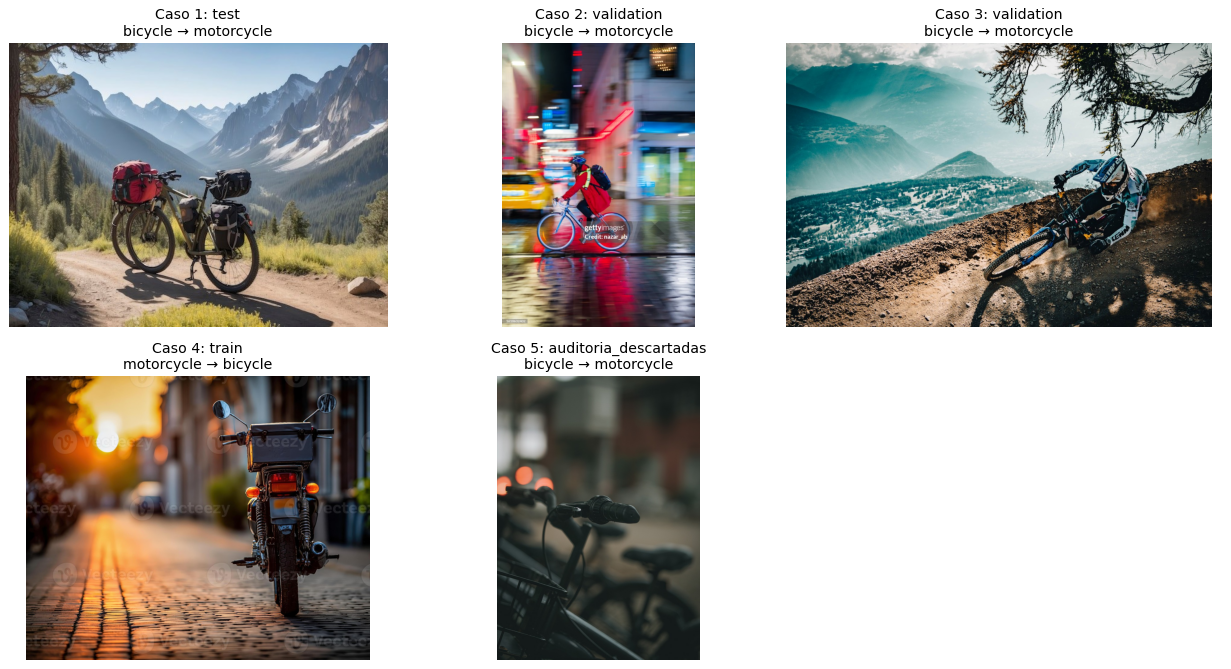

Estos casos son diagnósticos; no se reentrena ni se modifica la selección.


In [25]:
# Reviso más errores, pero las métricas finales siguen siendo las de test.
# Aquí solo hago predicciones sobre validación y entrenamiento, sin volver a entrenar.
audit_rows = []
for split in ["test", "validation", "train"]:
    audit_ds = keras.utils.image_dataset_from_directory(
        SPLIT_DIR / split, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=False, class_names=class_names, label_mode="int")
    audit_paths = list(audit_ds.file_paths)
    actual = np.concatenate([y.numpy() for _, y in audit_ds])
    prob = model.predict(audit_ds, verbose=0)
    predicted = prob.argmax(axis=1)
    for i in np.flatnonzero(actual != predicted):
        audit_rows.append({"image": audit_paths[i], "split": split,
                           "real": class_names[actual[i]], "prediction": class_names[predicted[i]],
                           "confidence": float(prob[i, predicted[i]])})

# También pruebo algunas fotos descartadas para ver cómo responde el modelo.
# Las miro por separado: no las sumo al test ni calculo una accuracy general con ellas.
AUDIT_EXTRA_PATHS = ['data_raw/bicycle/1ea6e3df4fb564c87135a3ab.jpg', 'data_raw/bicycle/2f7274c1b24ef520b8067e12.jpg', 'data_raw/bicycle/32acb57d77841c43d2425b67.jpg', 'data_raw/bicycle/377e4326b125e74c2d73fdb2.jpg', 'data_raw/bicycle/66c7d46f76637af07cd42bf2.jpg', 'data_raw/bicycle/671a78d24f73247c417b349b.jpg', 'data_raw/bicycle/75ed9932b3aab88ba0463e89.jpg', 'data_raw/bicycle/acbe3f4240398da3f8cd0e69.jpg', 'data_raw/bicycle/cbc77b0b4c23641b56dee356.jpg', 'data_raw/bicycle/cc1cedfea7f2eed8ecd8a465.jpg', 'data_raw/bicycle/d33f6554064393bbc92a24f3.jpg', 'data_raw/bicycle/edf823688e7f36365c00a07f.jpg', 'data_raw/bicycle/f55ceb57ecb6c4b0b63b1c0a.jpg']
for path in AUDIT_EXTRA_PATHS:
    if not Path(path).exists():
        continue
    image = keras.utils.load_img(path, target_size=IMG_SIZE, interpolation="bilinear")
    array = keras.utils.img_to_array(image)[None, ...]
    prob = model.predict(array, verbose=0)[0]
    predicted = class_names[int(prob.argmax())]
    if predicted != "bicycle":
        audit_rows.append({"image": path, "split": "auditoria_descartadas",
                           "real": "bicycle", "prediction": predicted,
                           "confidence": float(prob.max())})
audit_errors = pd.DataFrame(audit_rows)
audit_errors.to_csv(REPORTS_DIR / "all_audit_errors.csv", index=False)
display(audit_errors.head(5))
if len(audit_errors):
    fig, axes = plt.subplots(int(np.ceil(min(5,len(audit_errors))/3)), 3, figsize=(15, 8), squeeze=False)
    for j, ax in enumerate(axes.ravel()):
        if j < min(5, len(audit_errors)):
            row = audit_errors.iloc[j]
            with Image.open(row["image"]) as im: ax.imshow(im)
            ax.set_title(f"Caso {j+1}: {row['split']}\n{row['real']} → {row['prediction']}")
        ax.axis("off")
    plt.tight_layout(); plt.show()
print("Estos casos son diagnósticos; no se reentrena ni se modifica la selección.")


,image,split,real,prediction,confidence,observacion_visual,causa_probable,mejora
0,dataset_8c8e855ccf33/test/bicycle/f140f944fc7c...,test,bicycle,motorcycle,0.631028,Las alforjas ocultan parte del cuadro y aument...,Las alforjas ocultan parte del cuadro y aument...,Añadir bicicletas con alforjas y distintas per...
1,dataset_8c8e855ccf33/validation/bicycle/04cd24...,validation,bicycle,motorcycle,0.521631,"Hay desenfoque de movimiento, lluvia, tráfico ...","Hay desenfoque de movimiento, lluvia, tráfico ...",Revisar a resolución completa y añadir fotos a...
2,dataset_8c8e855ccf33/validation/bicycle/cb4682...,validation,bicycle,motorcycle,0.684906,"La bicicleta está inclinada sobre el suelo, co...","La bicicleta está inclinada sobre el suelo, co...",Incluir bicicletas inclinadas o estacionadas d...
3,dataset_8c8e855ccf33/train/motorcycle/aec0f04b...,train,motorcycle,bicycle,0.540782,La motocicleta se ve desde atrás y su silueta ...,La motocicleta se ve desde atrás y su silueta ...,Incluir vistas traseras de ambas clases y revi...
4,data_raw/bicycle/1ea6e3df4fb564c87135a3ab.jpg,auditoria_descartadas,bicycle,motorcycle,0.721529,El encuadre muestra principalmente un manillar...,El encuadre muestra principalmente un manillar...,Solicitar una vista completa o definir un crit...


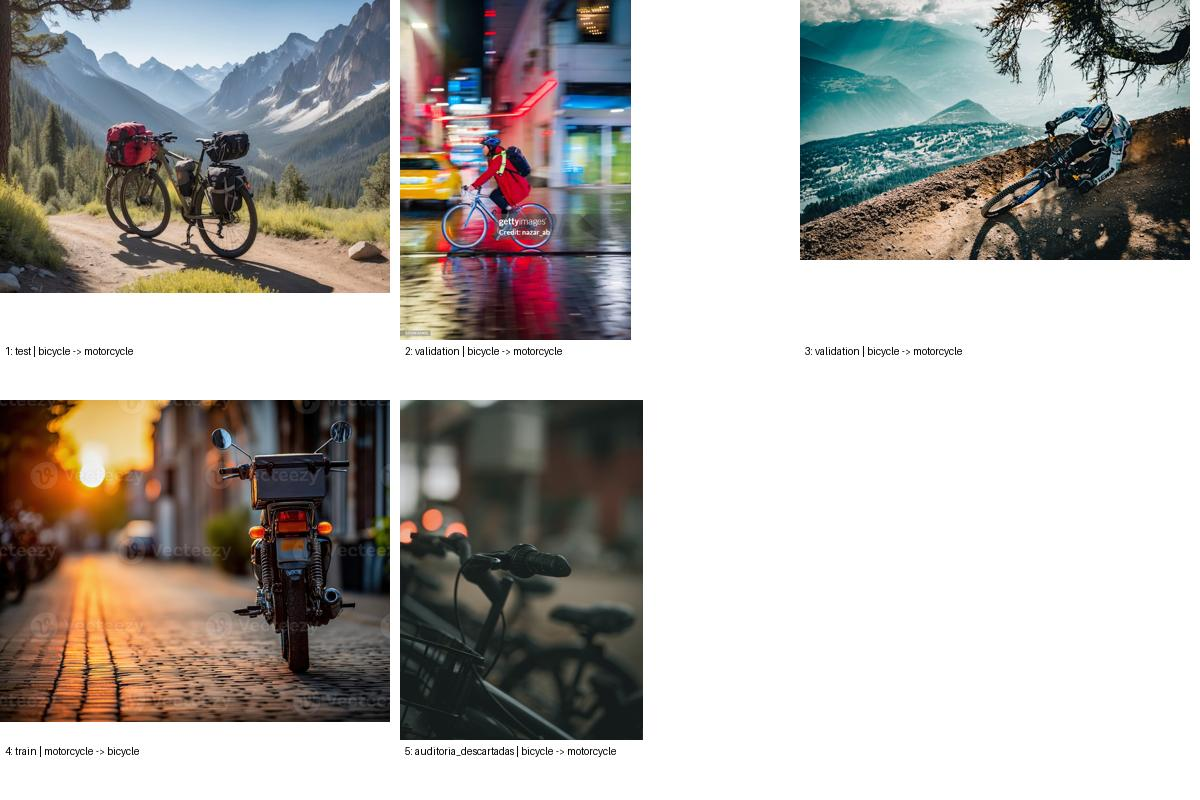

In [26]:
# Muestro los cinco casos revisados. Los archivos están en el ZIP.
reviewed = pd.read_csv(REPORTS_DIR / "five_errors_reviewed.csv")
display(reviewed)
with Image.open(REPORTS_DIR / "five_errors.jpg") as im:
    display(im.copy())


# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [24]:
def predict_external_image(path):
    deployed = keras.models.load_model(ARTIFACTS_DIR / "selected_model.keras")
    with Image.open(path) as original:
        img = ImageOps.exif_transpose(original).convert("RGB")
    # Preparo la foto con el mismo tamaño y rango que usé al entrenar.
    x = tf.image.resize(np.asarray(img, dtype="float32"), IMG_SIZE, method="bilinear")[None, ...]
    probs = deployed.predict(x, verbose=0)[0]
    display(pd.DataFrame({"class": class_names, "probability": probs}))
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[int(probs.argmax())]} — p={probs.max():.3f}"); plt.show()
    return probs

EXTERNAL_IMAGE_PATH = Path("imagen_externa.jpg")
if EXTERNAL_IMAGE_PATH.exists():
    external_probabilities = predict_external_image(EXTERNAL_IMAGE_PATH)
else:
    print("Opcional: carga imagen_externa.jpg y reejecuta esta celda.")


Opcional: carga imagen_externa.jpg y reejecuta esta celda.


# Cierre conceptual

**Transfer learning con la base congelada:** aprovecho las características que EfficientNet ya aprendió con ImageNet. Los pesos de esa base no cambian; lo que se entrena es la nueva capa que clasifica las tres clases del taller. GlobalAveragePooling y Dropout no agregan pesos entrenables. Esto permite partir de algo que ya sabe reconocer características de imágenes, en lugar de aprender todo desde cero.

**Fine-tuning:** después del primer entrenamiento, permito que cambien algunos pesos de la parte final de la base, además de los de la cabeza de clasificación. Así el modelo puede adaptarse un poco más a los vehículos. Uso una tasa pequeña para no cambiar demasiado lo que ya había aprendido y mantengo BatchNormalization congelada y en modo de inferencia. Como cambiaron las capas entrenables, debo recompilar el modelo.

**Entrenar una CNN desde cero:** los pesos empiezan con valores aleatorios y la red tiene que aprender tanto las características de las imágenes como la clasificación usando mis datos. No aprovecha lo aprendido con ImageNet. Por eso normalmente necesita más imágenes y tiempo de entrenamiento, y con un dataset pequeño es más fácil que se sobreajuste.

Documentación consultada: [EfficientNet de Keras](https://keras.io/api/applications/efficientnet/efficientnet_models/), [transfer learning y fine-tuning](https://keras.io/guides/transfer_learning/) y [DDGS](https://pypi.org/project/ddgs/).


# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# Checklist de entrega

- [x] Problema de tres clases y búsquedas documentados.
- [x] Descarga y revisión inicial de imágenes, con exclusiones registradas.
- [x] Partición train/validation/test y comprobación de duplicados exactos.
- [x] EfficientNetB0 congelada entrenada y curvas guardadas.
- [x] Evaluación final y métricas por clase.
- [x] Fine-tuning ejecutado y comparación antes/después.
- [x] Cinco errores reales analizados, con origen explícito; solo uno corresponde a test.
- [x] Conclusiones y diferencias conceptuales explicadas.

**Limitación respecto de la meta de adquisición:** quedaron menos de 100 imágenes por clase. La extensión de imagen externa y el reto adicional son opcionales; se dejó implementada la función de inferencia externa, sin afirmar que se ejecutó con una fotografía nueva.


# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |